# 🔍 EduGuard AI — Stage 5: Explainability (SHAP) & Algorithmic Fairness Audit

**Course / Project:** EduGuard AI (Final-Year Project)  
**Module:** `notebooks/05_model_explainability.ipynb`  
**Objectives:**  
1. Demystify tree-based model decisions using **TreeSHAP** (global and local feature attributions).  
2. Provide local student waterfall profiles and automated **plain-English diagnostic explanations**.  
3. Audit algorithmic fairness and parity across sensitive demographic (`sex`, `address`) and institutional (`school`) slices on **held-out test data only**.  
**Stack:** Python 3.11+, SHAP, scikit-learn, XGBoost, matplotlib, seaborn, pandas  

---

## 📖 1. The Ethical Imperative for Explainability in Education

Machine learning models deployed in educational counseling operate in a high-stakes, human-centered environment. If an AI system flags a student as "High Risk" without explanation:
- Counselors cannot determine what specific academic or behavioral support the student needs.
- Students and parents may feel unfairly stigmatized by an opaque algorithm.
- Undetected historical biases could systematically disadvantage specific student groups.

By integrating **TreeSHAP** (Lundberg et al., Nature Machine Intelligence 2020), EduGuard AI provides mathematically principled, game-theoretic explanations for every prediction.


## 🧠 2. Conceptual Deep Dive: Feature Importance vs. SHAP Contribution vs. Causation

One of the most frequent misconceptions in applied machine learning is conflating **feature importance**, **SHAP contributions**, and **causation**. Understanding their differences is essential for ethical educational decision-support.

| Dimension | 1. Global Feature Importance (e.g. MDI / Gini) | 2. SHAP Contribution (Local Shapley Values) | 3. Real-World Causation (Counterfactual Reality) |
| :--- | :--- | :--- | :--- |
| **Scope** | Global (entire dataset / forest). | Local (individual student) + Global (aggregated). | Physical reality / real-world causality. |
| **Question Answered** | *"Which features did the trees split on most often to reduce total impurity?"* | *"For student Maria, exactly how many percentage points did each feature add or subtract from her predicted risk?"* | *"If we change this factor in Maria's life, will her final exam grade actually improve?"* |
| **Directionality** | **Non-directional.** Shows magnitude only (cannot tell if a feature increases or decreases risk). | **Directional & Signed.** Explicitly indicates whether a feature elevates ($+$) or mitigates ($-$) risk. | Governed by causal mechanisms and confounding variables. |
| **Additivity** | No additive baseline. Numbers are arbitrary relative scores. | **Strictly Additive:** $\text{Prediction} = \text{Base Value} + \sum \text{SHAP}_i$. | Non-additive; interventions often have non-linear spillover effects. |
| **Key Limitation** | Heavily biased toward high-cardinality continuous features; ignores feature interactions. | Reflects correlations in the training data; **does not prove causation**. | Requires randomized controlled trials (RCTs) or causal graphical models (DAGs). |

---

### 🎓 Student-Friendly Example: The Absences Paradox

Imagine a student named **Maria**:
- The model predicts Maria has a **$75\%$ probability of failing math**.
- Her SHAP waterfall plot reveals that `absences = 18` is the top factor, adding **$+18.5\%$ to her risk score**.

#### ❌ The Naive / Dangerous Mistake (Assuming Causation):
An administrator mistakenly interprets the SHAP value as a direct causal lever:
> *"The model says absences cause 18.5% of her risk. If we threaten detention and force Maria to attend every class, her risk will instantly drop!"*

#### Why That Fails (Confounding & Reality):
*Why* was Maria absent 18 times?
1. Maria may be suffering from an untreated chronic medical condition.
2. Maria may work a late-night part-time job to help her family pay rent.
3. Maria may have fallen behind early in the semester, felt hopeless, and started skipping class out of anxiety.

Simply forcing physical attendance does not cure an illness, alleviate poverty, or teach missed math concepts. 

#### ✅ The Responsible, Ethical AI Stance:
SHAP values are **diagnostic flags**, not causal buttons:
- The $+18.5\%$ SHAP value alerts the counselor: *"Maria's high absences strongly correlate with academic trouble in our historical cohort."*
- The human counselor conducts a compassionate check-in to uncover the *root cause*.
- Interventions target the underlying barrier (e.g., offering flexible tutoring, health services, or remedial math instruction).


In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML, Image

# Set plotting defaults
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10

# Robust project root resolution
current_dir = Path.cwd().resolve()
if (current_dir / "reports").exists():
    ROOT_DIR = current_dir
elif (current_dir.parent / "reports").exists():
    ROOT_DIR = current_dir.parent.resolve()
else:
    ROOT_DIR = Path("D:/eduguard-ai").resolve()

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.config import SENSITIVE_FEATURES, RISK_THRESHOLDS
from src.explainability import (
    get_cached_explainer, 
    get_transformed_features, 
    global_importance, 
    explain_student,
    get_output_scale_info
)
from src.fairness import comprehensive_fairness_audit, interpret_fairness_audit
from src.features import prepare_scenario_data

print("EduGuard AI Stage 5 Environment Active.")
print(f"Project Root: {ROOT_DIR}")


EduGuard AI Stage 5 Environment Active.
Project Root: D:\eduguard-ai


## 🌍 3. Global Explainability Across Modeling Scenarios

Let's examine which features drive predictions across the entire student population using **TreeSHAP Beeswarm Summary Plots**.

### Output Scale of SHAP Values:
As explained in `src/explainability.py`:
- For our **RandomForestClassifier** champion models, SHAP values are computed on the **probability scale $[0.0, 1.0]$**.
- A positive SHAP value of $+0.10$ means that feature increased the student's probability of being at-risk by **$10$ percentage points**.
- The cohort baseline (expected value $E[f(x)]$) represents the historical at-risk prevalence.


,feature,mean_abs_shap
0,failures_flag,0.0513
1,failures,0.0473
2,subject_portuguese,0.0399
3,subject_math,0.0373
4,school_MS,0.0213
5,school_GP,0.0187
6,alcohol_total,0.0152
7,higher_yes,0.0135
8,higher_no,0.0120
9,absences,0.0118


Scenario A SHAP Beeswarm Summary Plot:


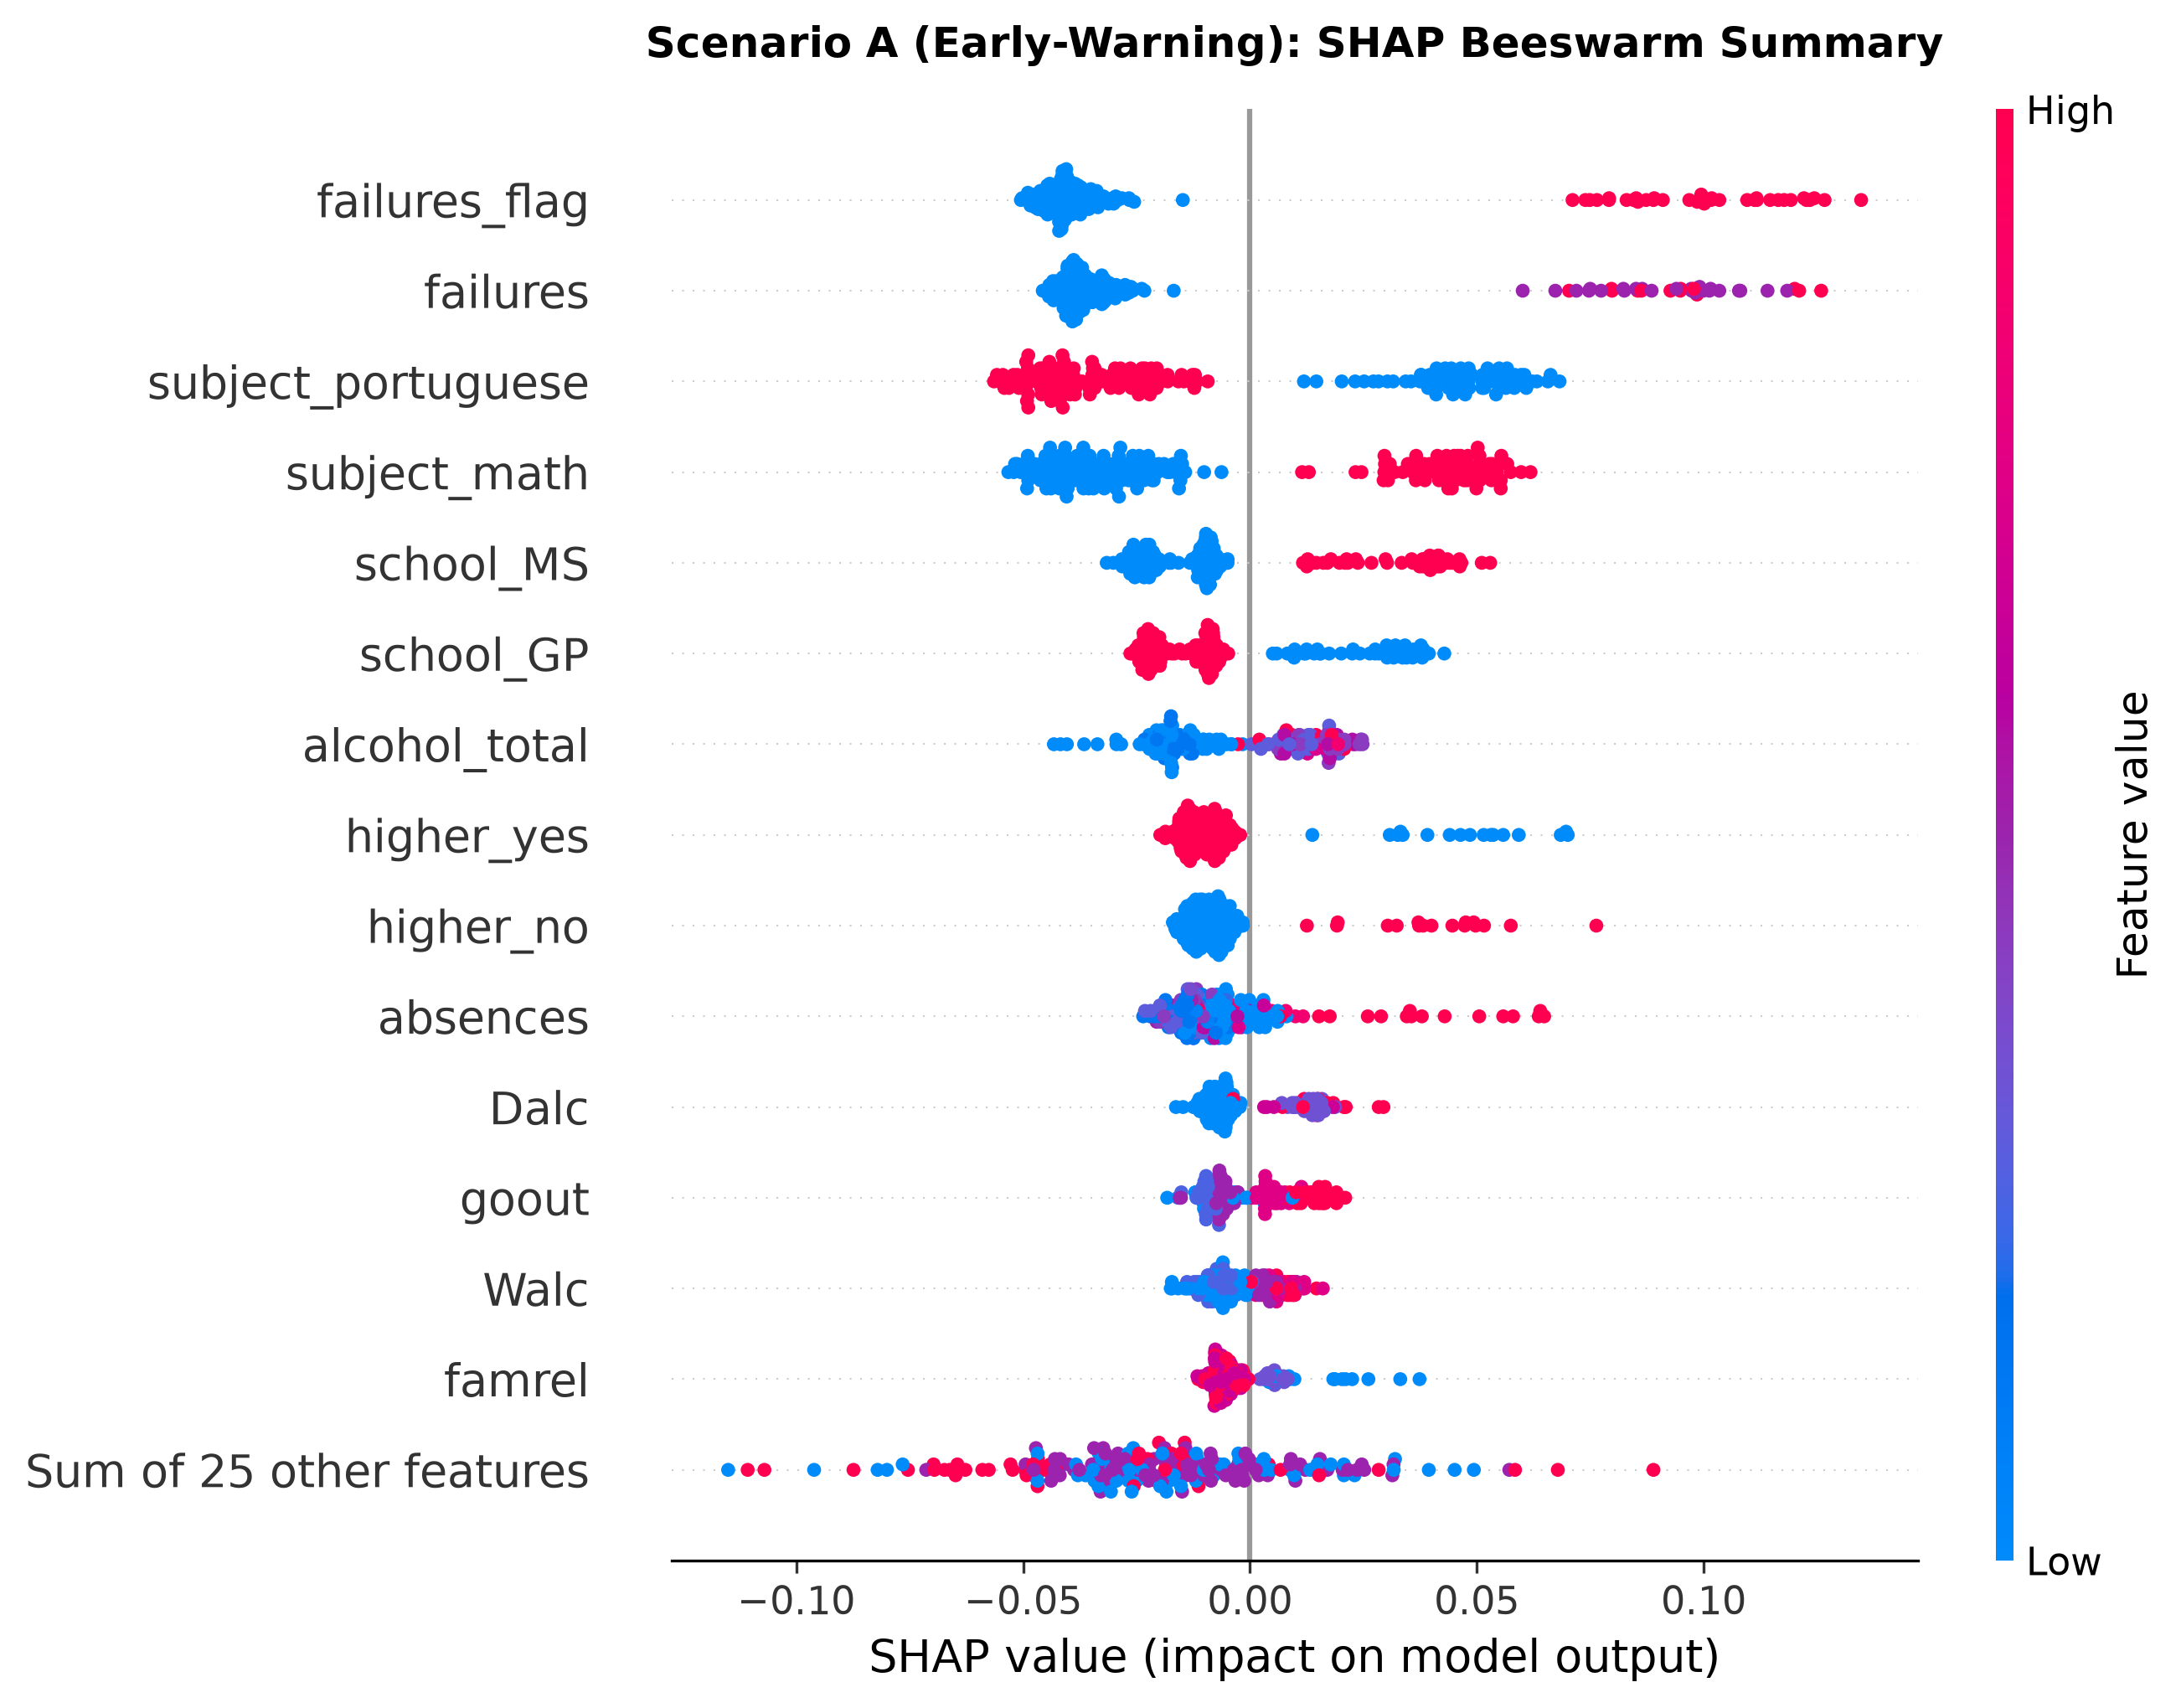

In [2]:
# 1. Load held-out test data
test_df = pd.read_csv(ROOT_DIR / "data" / "processed" / "test.csv")

# 2. Ingest Scenario A Explainer
explainer_a, prep_a, names_a = get_cached_explainer("A", "classification")
X_a, _, _, _, _ = prepare_scenario_data(test_df, scenario="A")
X_trans_a = prep_a.transform(X_a)

# 3. Compute Global Feature Importance Table
imp_a = global_importance(explainer_a, X_trans_a, feature_names=names_a)

display(HTML("<h3>📋 Scenario A (Early-Warning): Top 10 Driving Features</h3>"))
display(imp_a.head(10).round(4))

# Display Scenario A Beeswarm Summary Plot
print("Scenario A SHAP Beeswarm Summary Plot:")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "shap_summary_scenario_a.png"), width=750))


### 🔍 Key Insights from Scenario A (Early-Warning):
1. **Past Academic History (`failures`, `failures_flag`):**
   Prior course failures are the single strongest behavioral predictor of future risk. Students with past failures experience large positive SHAP shifts.
2. **Academic Subject Context (`subject_math` vs. `subject_portuguese`):**
   Enrolling in Mathematics elevates baseline risk compared to Portuguese, reflecting historical difficulty curves.
3. **Engagement & Lifestyle (`absences`, `studytime`, `alcohol_total`, `famrel`):**
   High absences and low study time consistently push risk higher, while strong family relationships (`famrel`) serve as a protective barrier.

---

## 📈 4. Scenario B (Mid-Semester Update) — The Primacy of Academic Momentum

In Scenario B, the model incorporates preliminary examination grades ($G1$ and $G2$) and academic trend ($	ext{grade\_trend} = G2 - G1$). Let's see how the feature hierarchy transforms.


,feature,mean_abs_shap
0,G2,0.1981
1,G1,0.1211
2,failures_flag,0.0234
3,subject_math,0.0232
4,failures,0.0213
5,subject_portuguese,0.0200
6,grade_trend,0.0122
7,school_GP,0.0093
8,school_MS,0.0088
9,alcohol_total,0.0084


Scenario B SHAP Beeswarm Summary Plot:


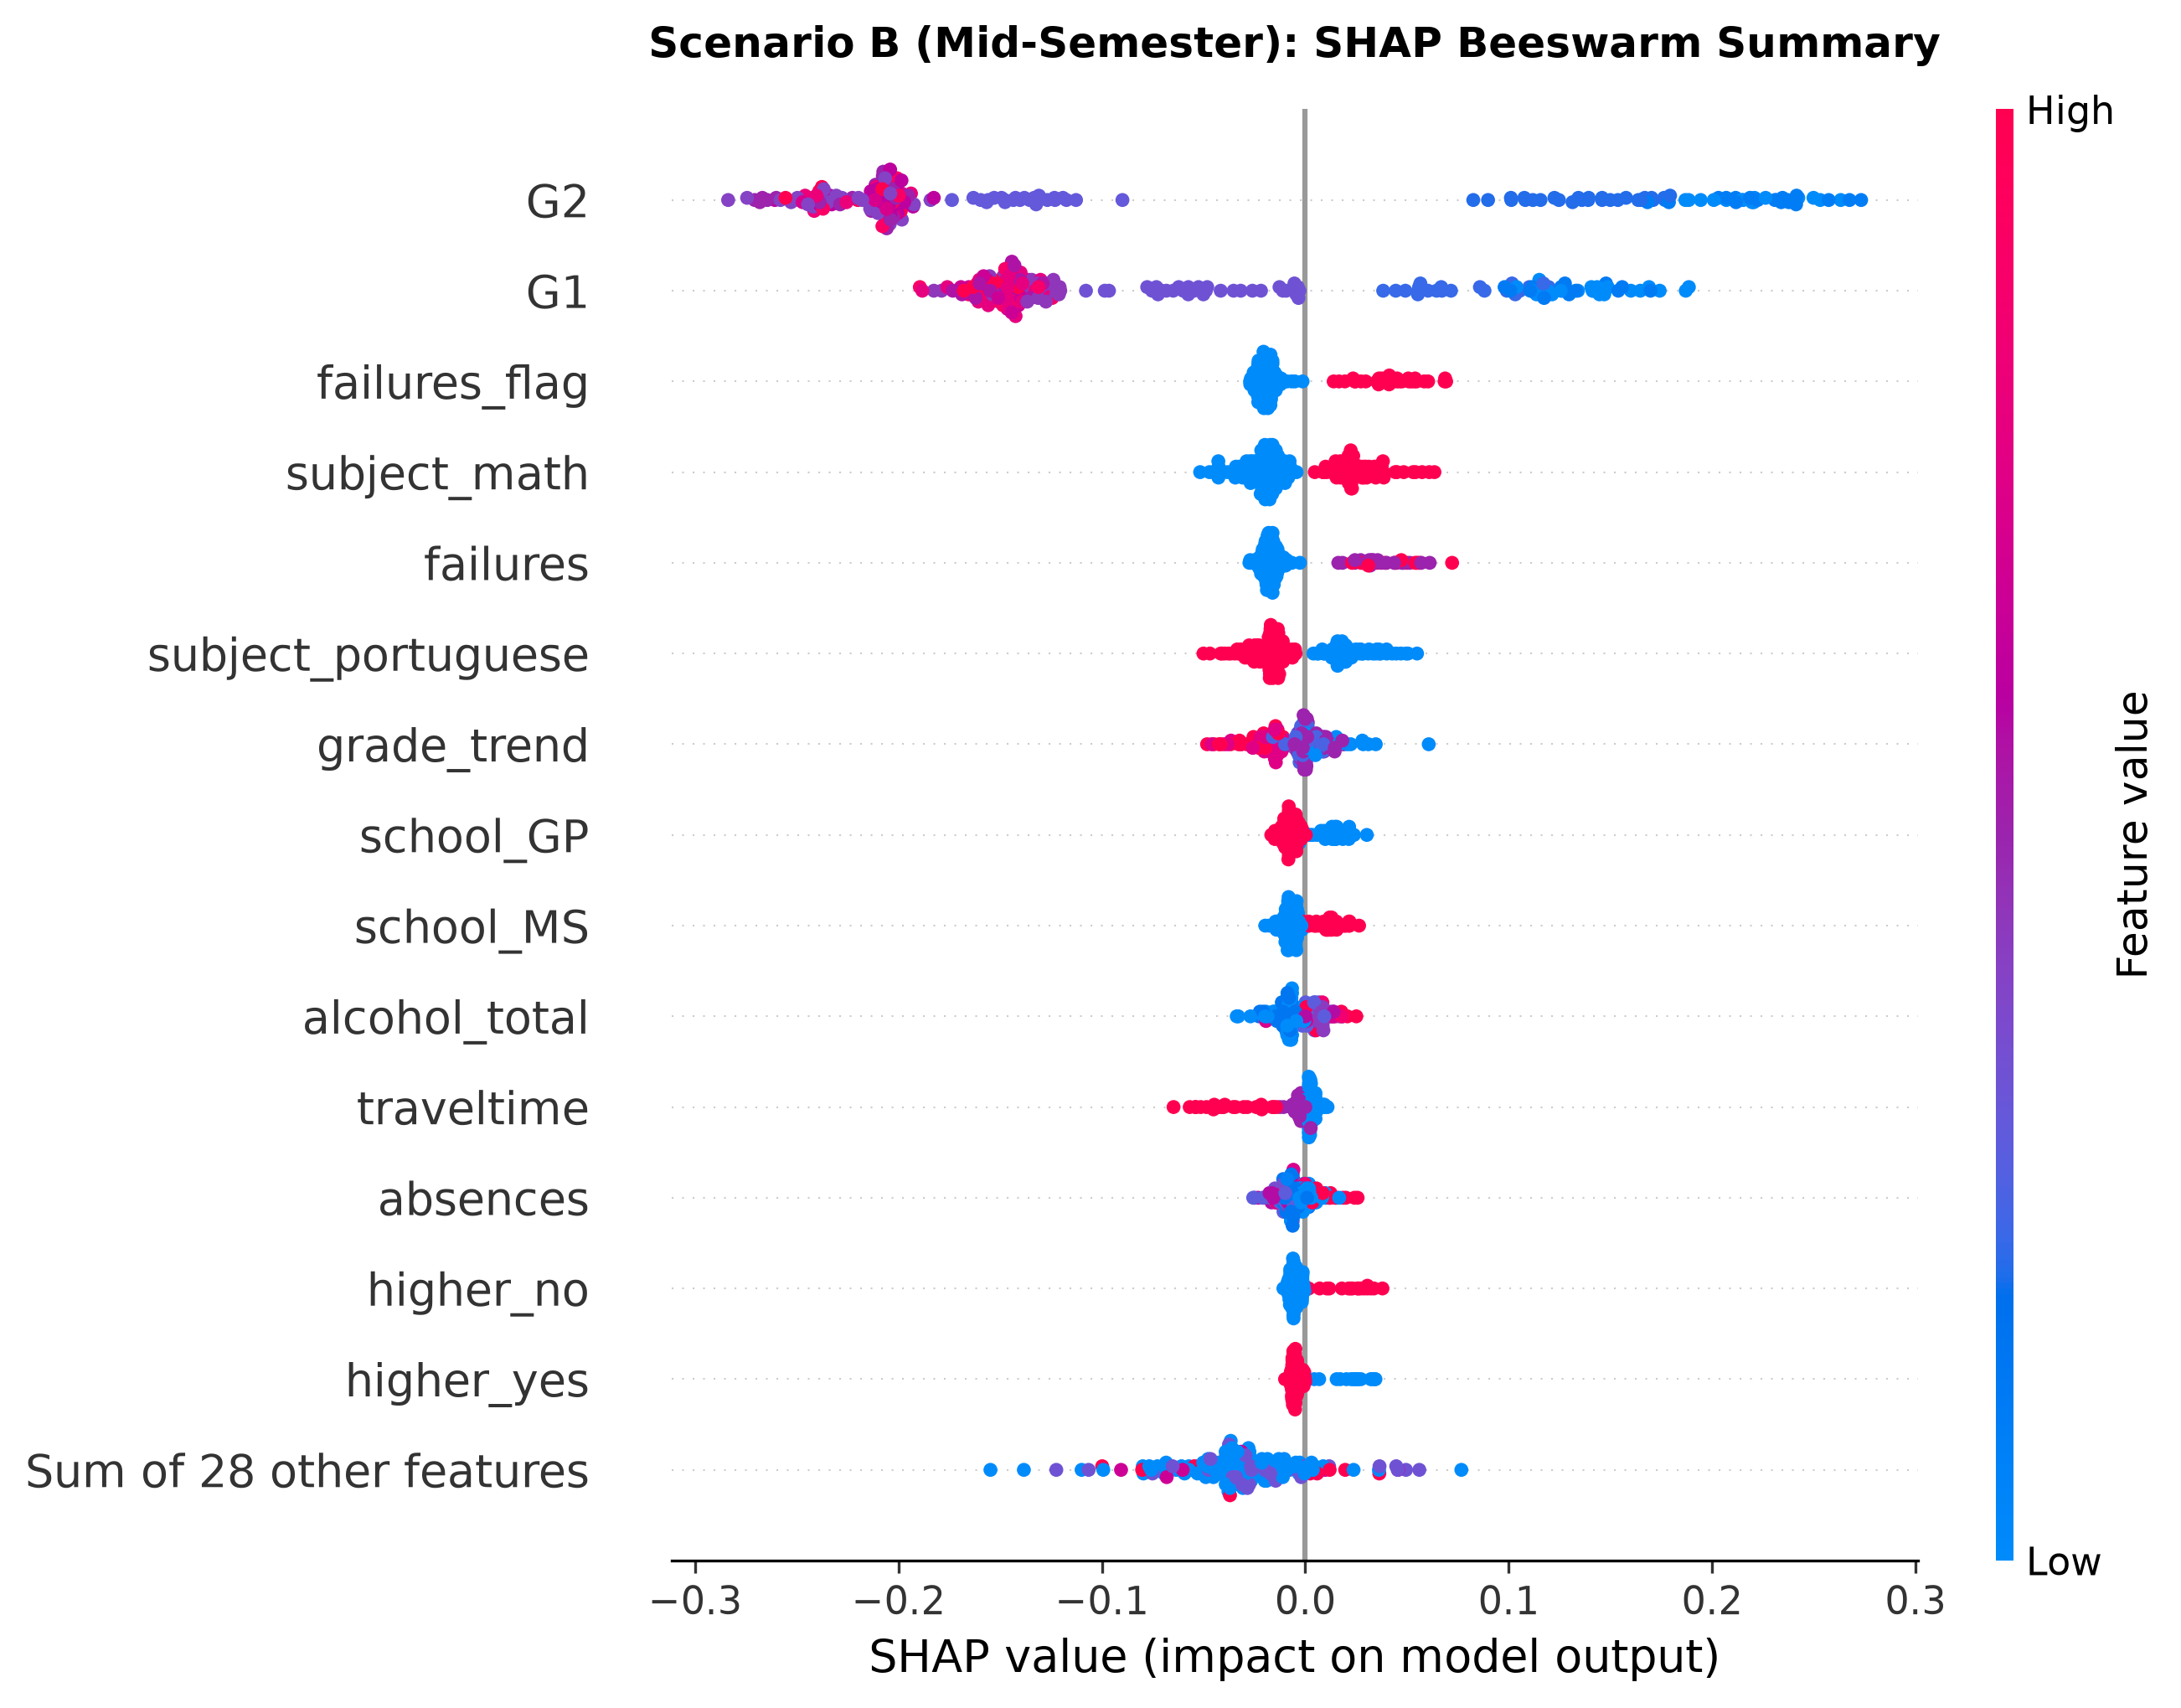

In [3]:
# Ingest Scenario B Explainer
explainer_b, prep_b, names_b = get_cached_explainer("B", "classification")
X_b, _, _, _, _ = prepare_scenario_data(test_df, scenario="B")
X_trans_b = prep_b.transform(X_b)

# Compute Global Feature Importance Table
imp_b = global_importance(explainer_b, X_trans_b, feature_names=names_b)

display(HTML("<h3>📋 Scenario B (Mid-Semester): Top 10 Driving Features</h3>"))
display(imp_b.head(10).round(4))

# Display Scenario B Beeswarm Summary Plot
print("Scenario B SHAP Beeswarm Summary Plot:")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "shap_summary_scenario_b.png"), width=750))


### 💡 Key Takeaway: The Dominance of Period 2 ($G2$)
- In Scenario B, **$G2$ (Period 2 grade)** overwhelmingly dominates all other features, followed by $G1$ and prior failures.
- This aligns with educational measurement theory: proximate academic performance is the strongest leading indicator of final attainment.
- Behavioral variables (absences, study habits) remain influential at the margin, especially for students hovering near the passing boundary ($9 - 10$ marks).


## 👤 5. Local Student-Level Explainability (SHAP Waterfalls)

A **SHAP Waterfall Plot** explains a single individual student's risk profile:
- **Baseline ($E[f(x)]$):** The cohort baseline risk (bottom of plot).
- **Red Arrows ($+$):** Features pushing the student's risk **higher**.
- **Blue Arrows ($-$)**: Protective features pulling the student's risk **lower**.
- **Final Output ($f(x)$):** The student's calibrated risk prediction.

Let's examine two contrasting student cases from the held-out test set:
1. **Case A:** A student flagged as **At-Risk** ($G3 < 10$).
2. **Case B:** A student predicted as **Passing** ($G3 \ge 10$).


Case A: At-Risk Student Local Waterfall Profile


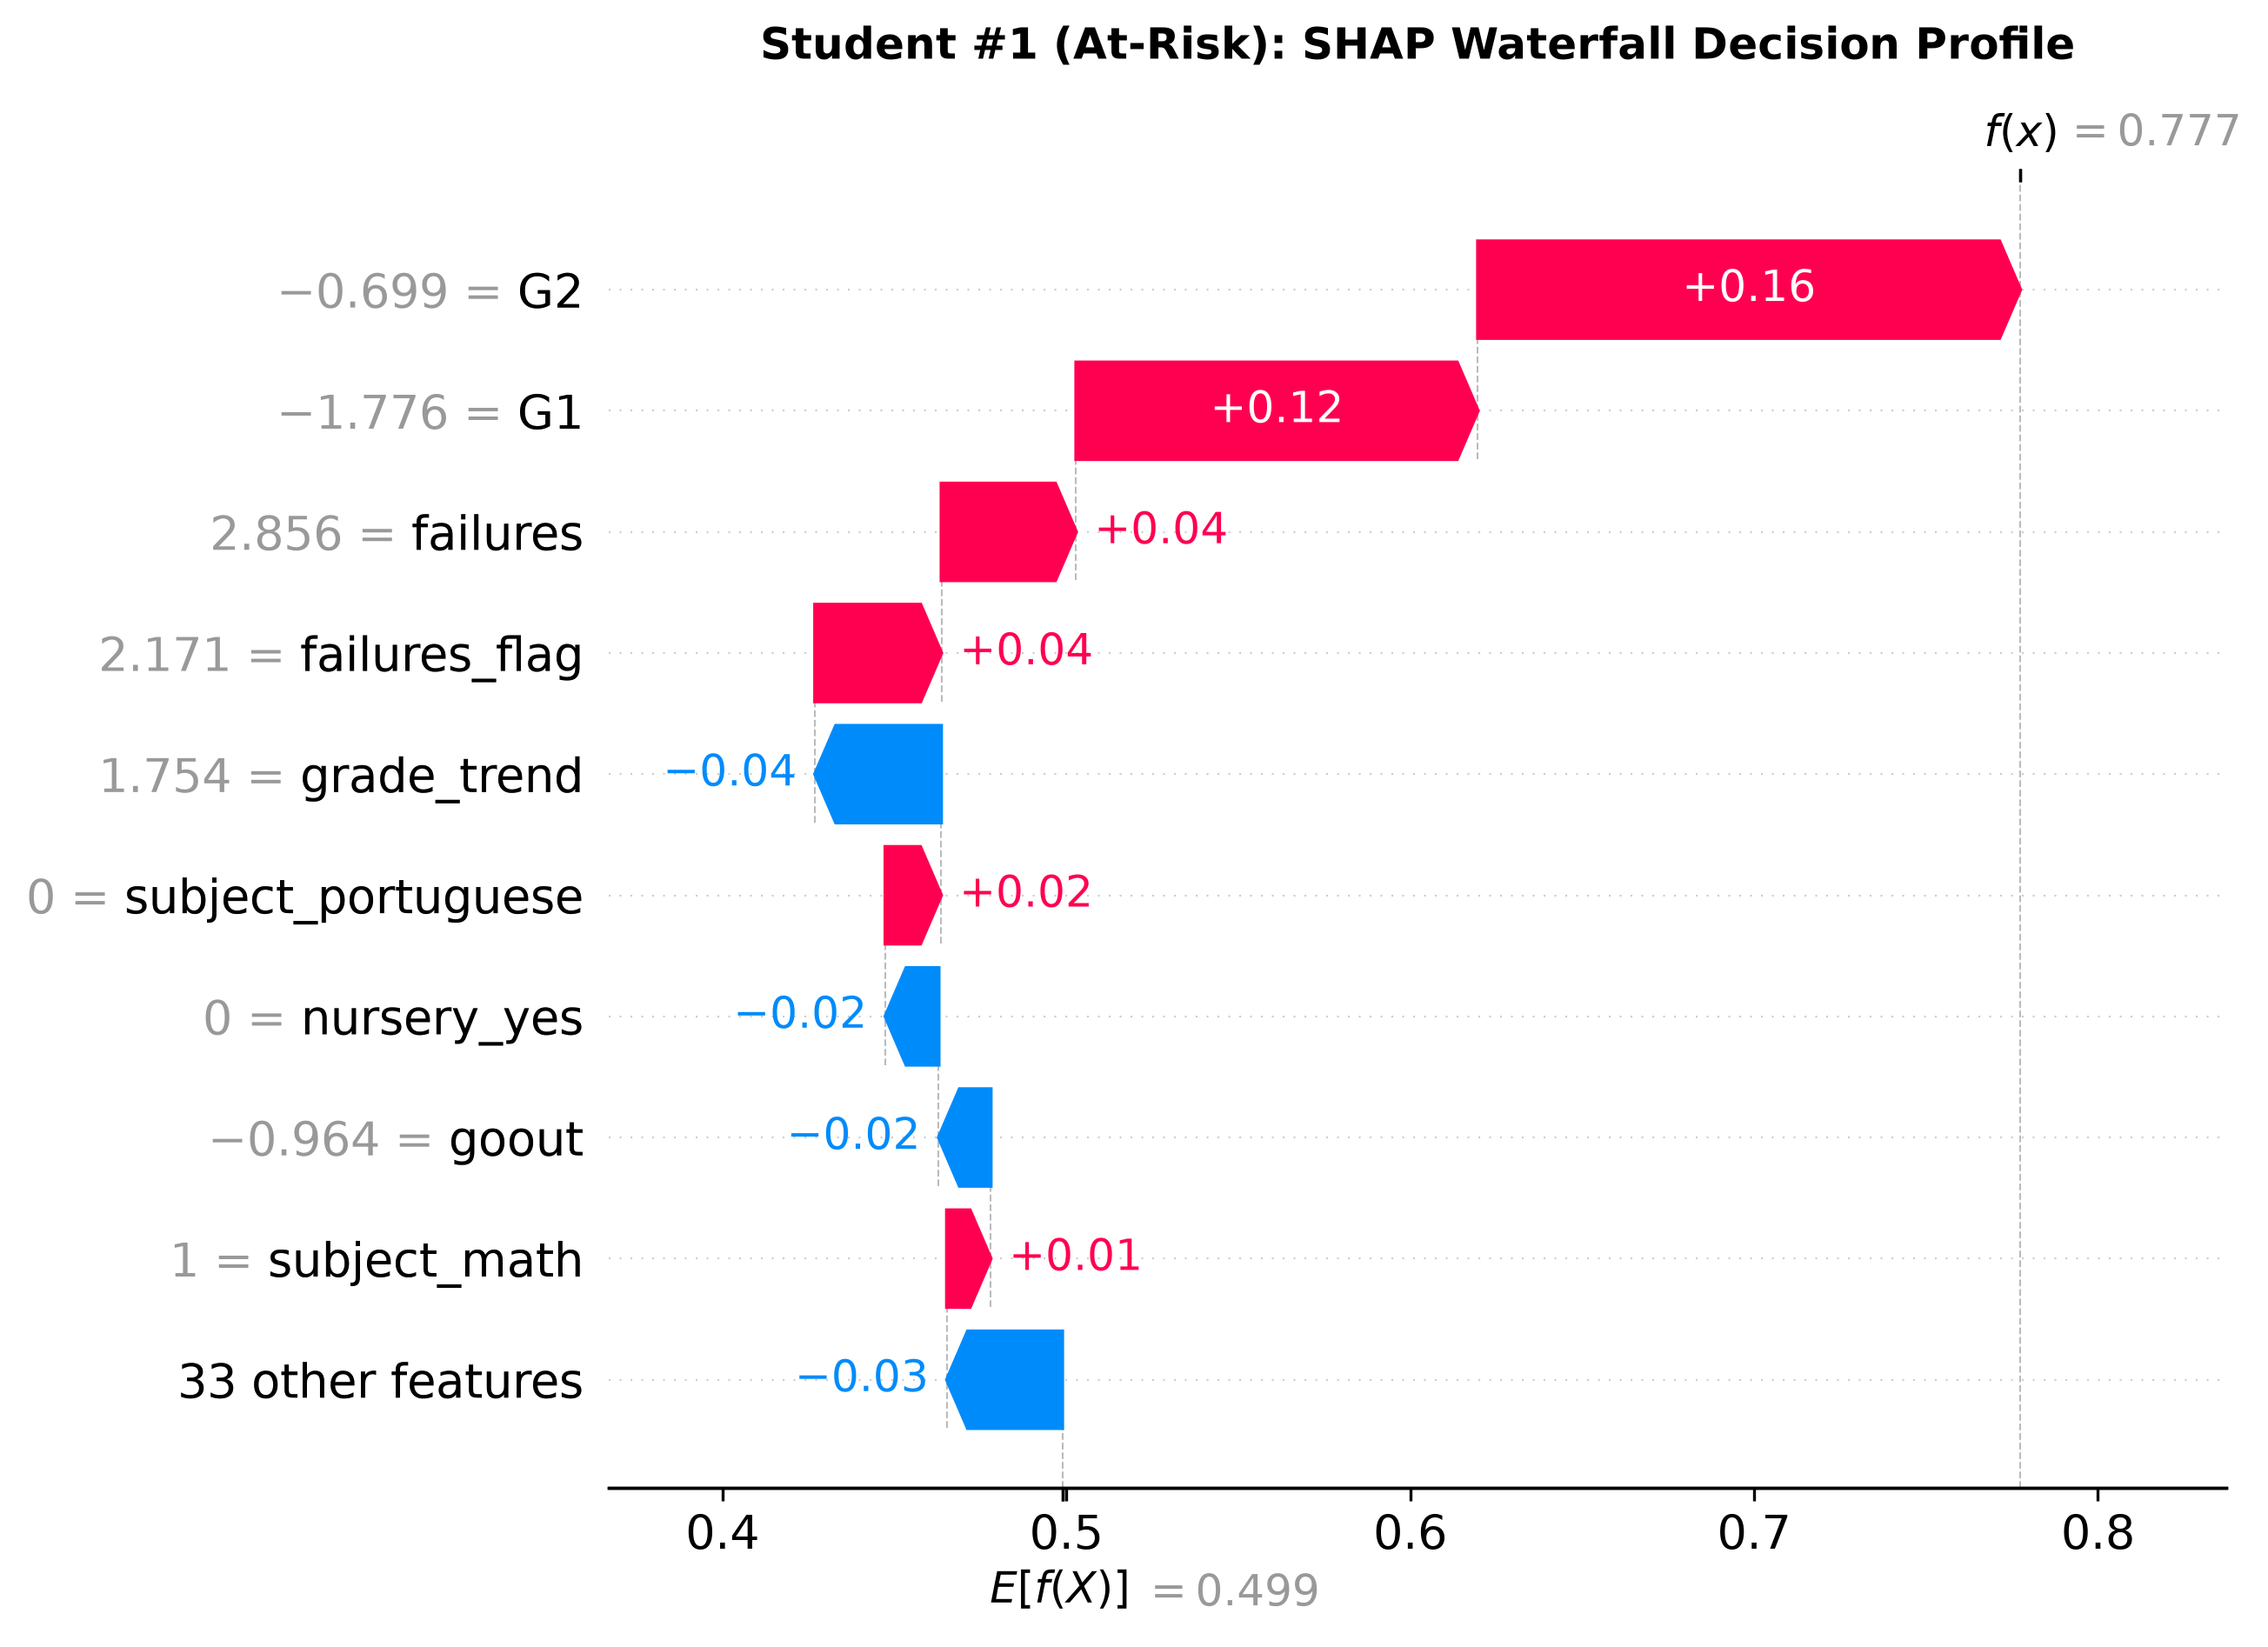

Case B: Passing Student Local Waterfall Profile


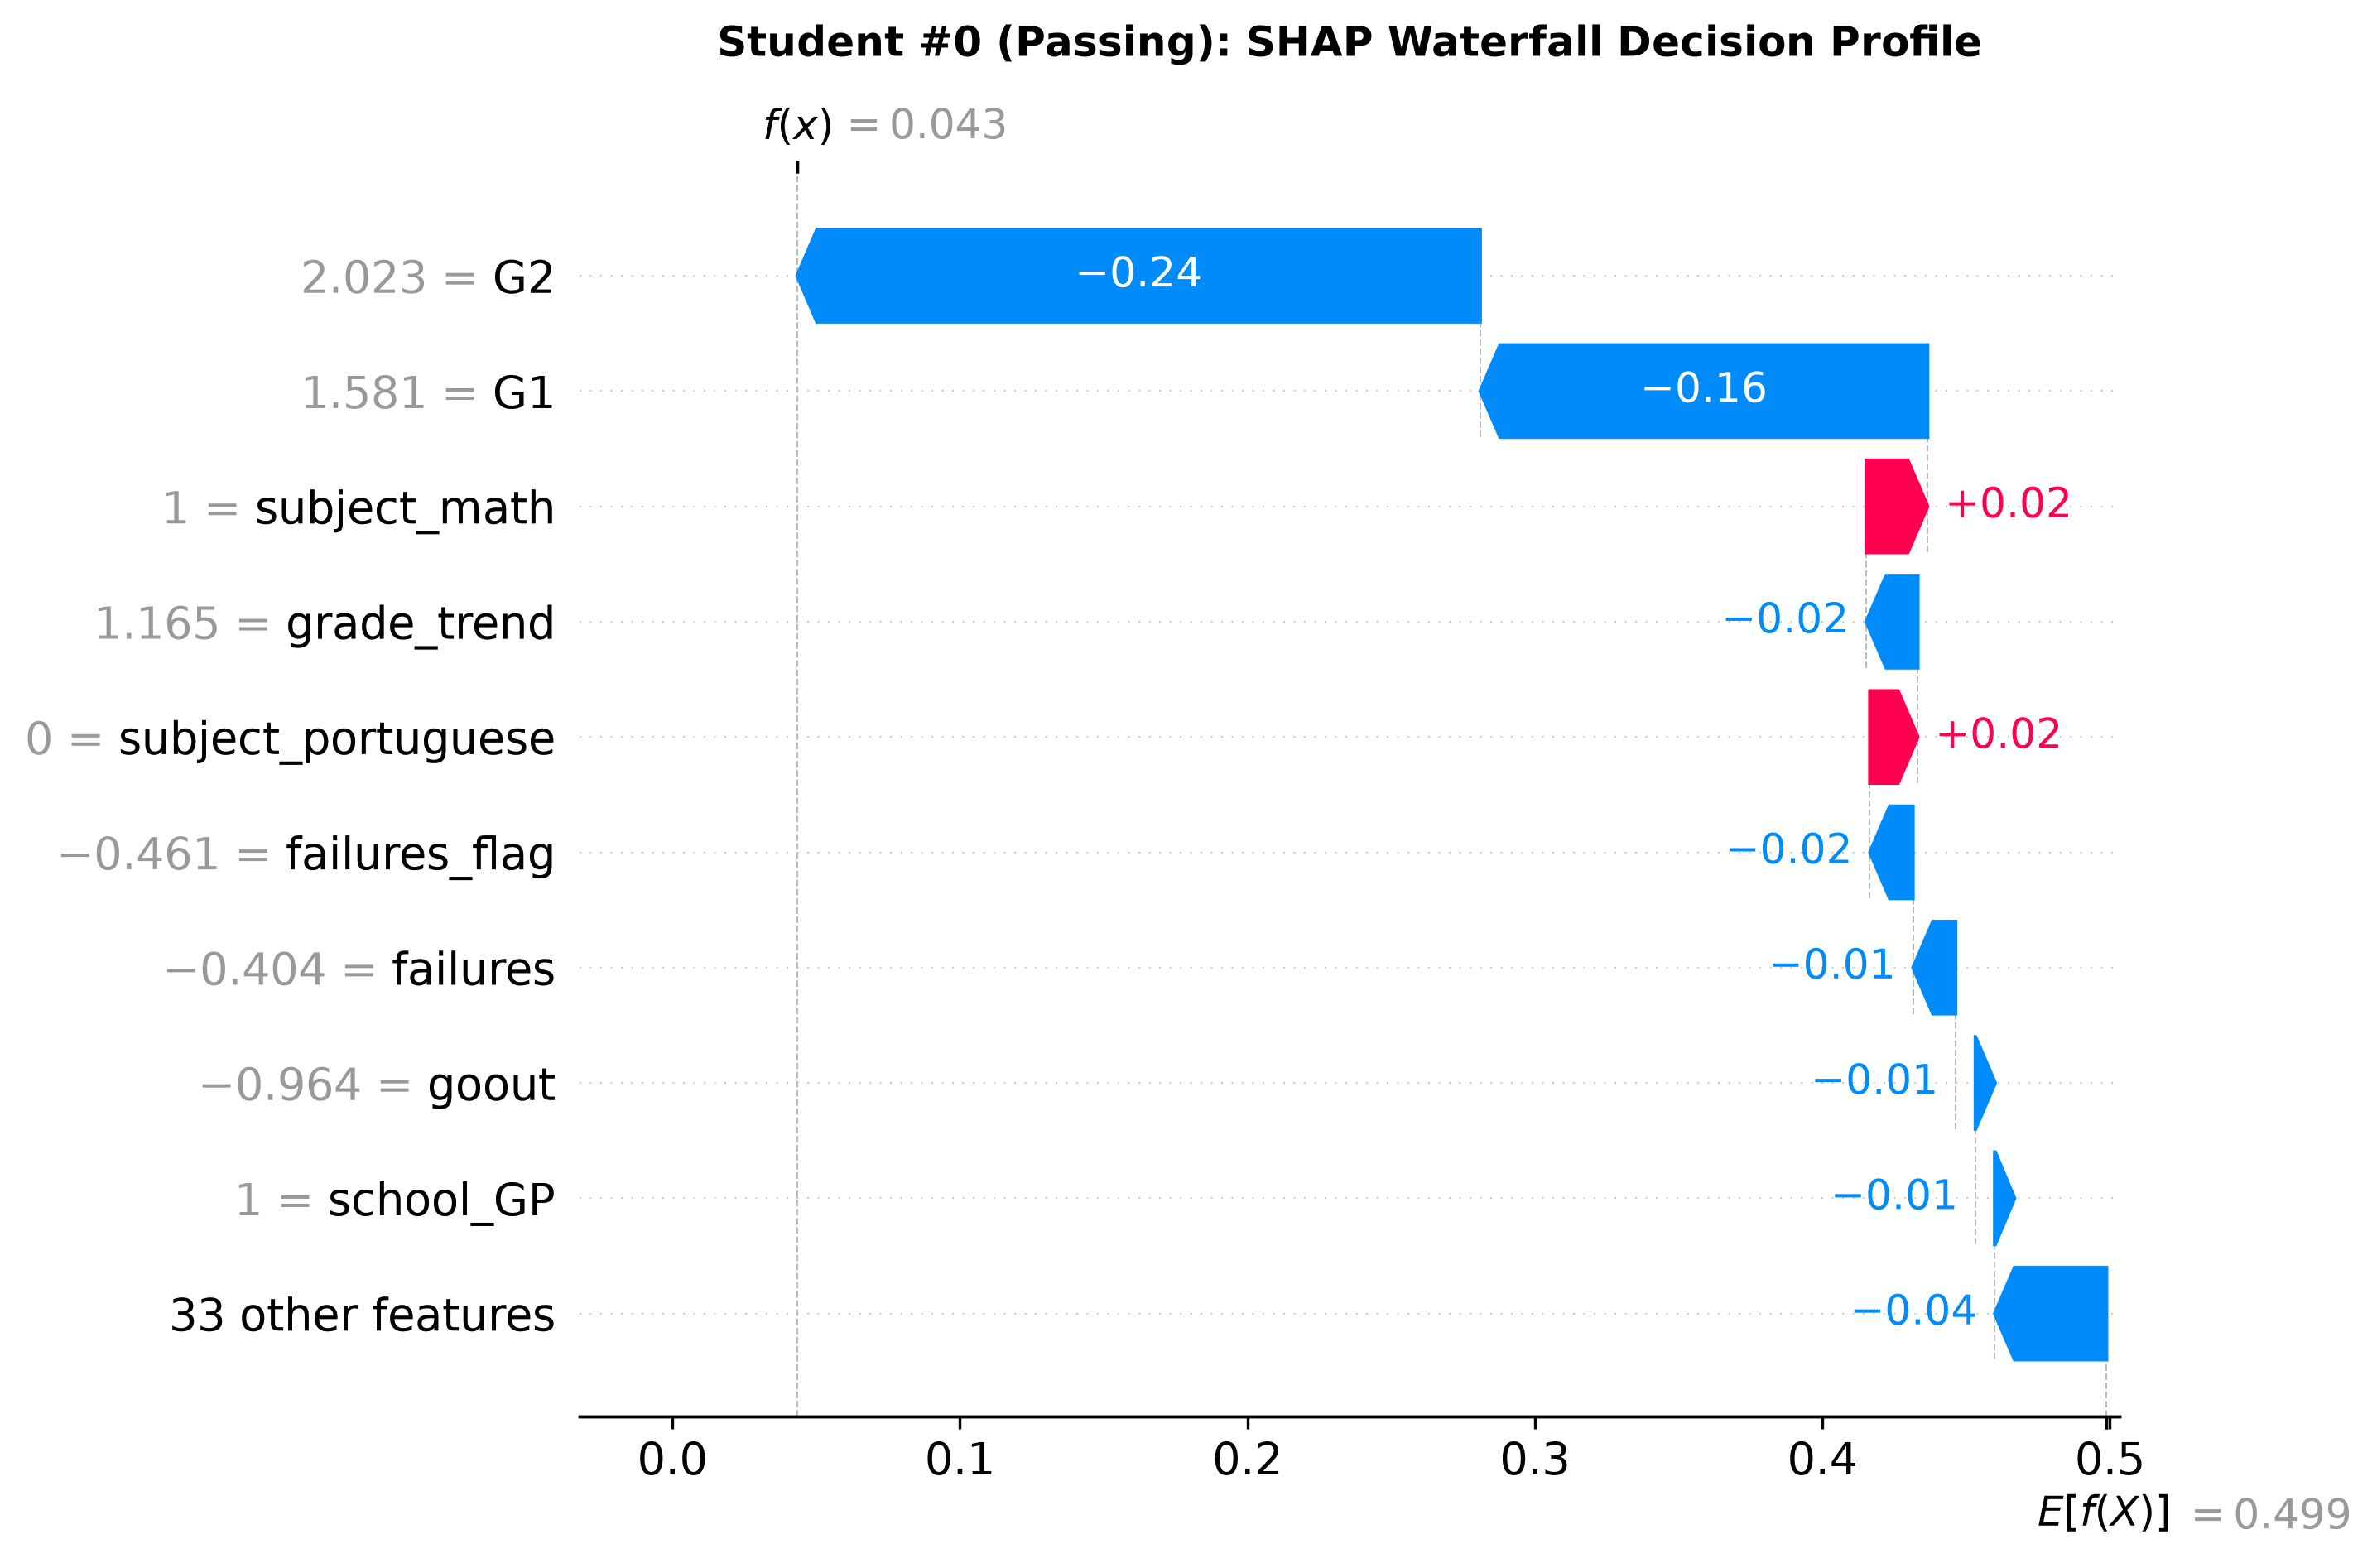

In [4]:
print("Case A: At-Risk Student Local Waterfall Profile")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "shap_waterfall_at_risk_scenario_b.png"), width=750))

print("Case B: Passing Student Local Waterfall Profile")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "shap_waterfall_passing_scenario_b.png"), width=750))


## 🗣️ 6. Automated Plain-English Diagnostic Explanations

School counselors and classroom teachers should not have to interpret complex SHAP plots during parent-teacher conferences.

EduGuard AI implements an automated diagnostic generator [`explain_student()`](file:///d:/eduguard-ai/src/explainability.py) that translates real SHAP values into factual, transparent, and non-stigmatizing plain-English sentences.


In [5]:
# Select an at-risk student from test.csv
at_risk_student = test_df[test_df["at_risk"] == 1].iloc[0]

explanation_risk = explain_student(
    at_risk_student, 
    explainer_b, 
    prep_b, 
    feature_names=names_b, 
    top_n=3, 
    is_classifier=True
)

display(HTML(f"<h4>🎓 Diagnostic Profile for Student (Actual G3: {at_risk_student['G3']})</h4>"))
print(f"Cohort Baseline Risk:   {explanation_risk['base_value'] * 100:.1f}%")
print(f"Predicted Student Risk: {explanation_risk['predicted_value'] * 100:.1f}%")
print(f"Net Risk Shift:         {explanation_risk['total_shift'] * 100:+.1f}%")

display(HTML("<b>Top Factors Elevating Risk:</b>"))
display(explanation_risk["top_positive"][["feature", "transformed_value", "shap_value", "direction"]].round(4))

display(HTML("<b>Top Protective Factors Mitigating Risk:</b>"))
display(explanation_risk["top_negative"][["feature", "transformed_value", "shap_value", "direction"]].round(4))

print()
print("📢 Generated Counselor Advisory Summary:")
print(explanation_risk["plain_english_summary"])


Cohort Baseline Risk:   49.9%
Predicted Student Risk: 77.7%
Net Risk Shift:         +27.9%


,feature,transformed_value,shap_value,direction
0,G2,-0.6993,0.1577,Elevates Risk
1,G1,-1.7758,0.1168,Elevates Risk
2,failures,2.8565,0.0392,Elevates Risk


,feature,transformed_value,shap_value,direction
0,grade_trend,1.7544,-0.0367,Mitigates Risk
1,nursery_yes,0.0000,-0.0155,Mitigates Risk
2,goout,-0.9637,-0.0151,Mitigates Risk



📢 Generated Counselor Advisory Summary:
Cohort baseline risk is 49.9%. The model estimates this student's risk at 77.7% (+27.9% net shift). Primary factors elevating academic risk: G2 (+15.8% risk), G1 (+11.7% risk), failures (+3.9% risk). Protective factors mitigating academic risk: grade_trend (-3.7% risk), nursery_yes (-1.6% risk), goout (-1.5% risk). Advisory Note: These SHAP values indicate model attributions, not direct causation. They should guide counseling conversations, not punitive measures.


## ⚖️ 7. Algorithmic Fairness & Bias Audit Across Subgroups

### The Ethical Governance Mandate (PROJECT_CONTEXT.md Rule 4.1):
- Protected attributes (`sex`, `address`, `school`, `famsize`, `guardian`, etc.) **must NEVER be predictive features**.
- They are retained strictly for post-hoc fairness audits on **held-out test data only**.

### Core Fairness Criteria Evaluated:
1. **Equal Opportunity (Recall Parity):**
   $$\text{Recall}_g = \frac{\text{TP}_g}{\text{TP}_g + \text{FN}_g}$$
   Does an at-risk female student have the same probability of receiving early support as an at-risk male student?
2. **Predictive Parity (Precision Parity):**
   $$\text{Precision}_g = \frac{\text{TP}_g}{\text{TP}_g + \text{FP}_g}$$
   When the model triggers an at-risk alert, is the alert equally credible across urban and rural students?
3. **Predictive Equality (False Positive Rate Parity):**
   $$\text{FPR}_g = \frac{\text{FP}_g}{\text{FP}_g + \text{TN}_g}$$
   Are passing students in one school more likely to receive disruptive false alarms?


In [6]:
from src.classification import load_classification_model, predict_risk

# Load Scenario B model and run predictions on test.csv at tuned threshold 0.15
model_b, meta_b = load_classification_model("B")
input_b = test_df.drop(columns=["G3", "at_risk", "student_key", "is_simulated"], errors="ignore")
pred_b = predict_risk(model_b, meta_b, input_b, threshold=0.15)

# Execute comprehensive fairness audit
fairness_audit_df = comprehensive_fairness_audit(
    df_test=test_df,
    y_true=test_df["at_risk"].values,
    y_pred=pred_b["predictions"],
    sensitive_cols=["sex", "address", "school"],
    features_used=meta_b["features_used"]
)

# Display formatted table
display_cols = [
    "attribute", "subgroup", "sample_size", "at_risk_count", 
    "selection_rate", "recall", "precision", "false_positive_rate", "small_sample_warning"
]
display(HTML("<h3>📋 Subgroup Fairness Audit Table (Held-Out Test Data, N = 203)</h3>"))
display(fairness_audit_df[display_cols])


,attribute,subgroup,sample_size,at_risk_count,selection_rate,recall,precision,false_positive_rate,small_sample_warning
0,sex,F,119,28,0.3025,0.9286,0.7222,0.1099,False
1,sex,M,84,20,0.3333,0.9000,0.6429,0.1562,False
2,address,R,50,16,0.4200,1.0000,0.7619,0.1471,True
3,address,U,153,32,0.2810,0.8750,0.6512,0.1240,False
4,school,GP,148,32,0.2703,0.8750,0.7000,0.1034,False
5,school,MS,55,16,0.4364,1.0000,0.6667,0.2051,True


Subgroup Fairness Parity Comparison Chart:


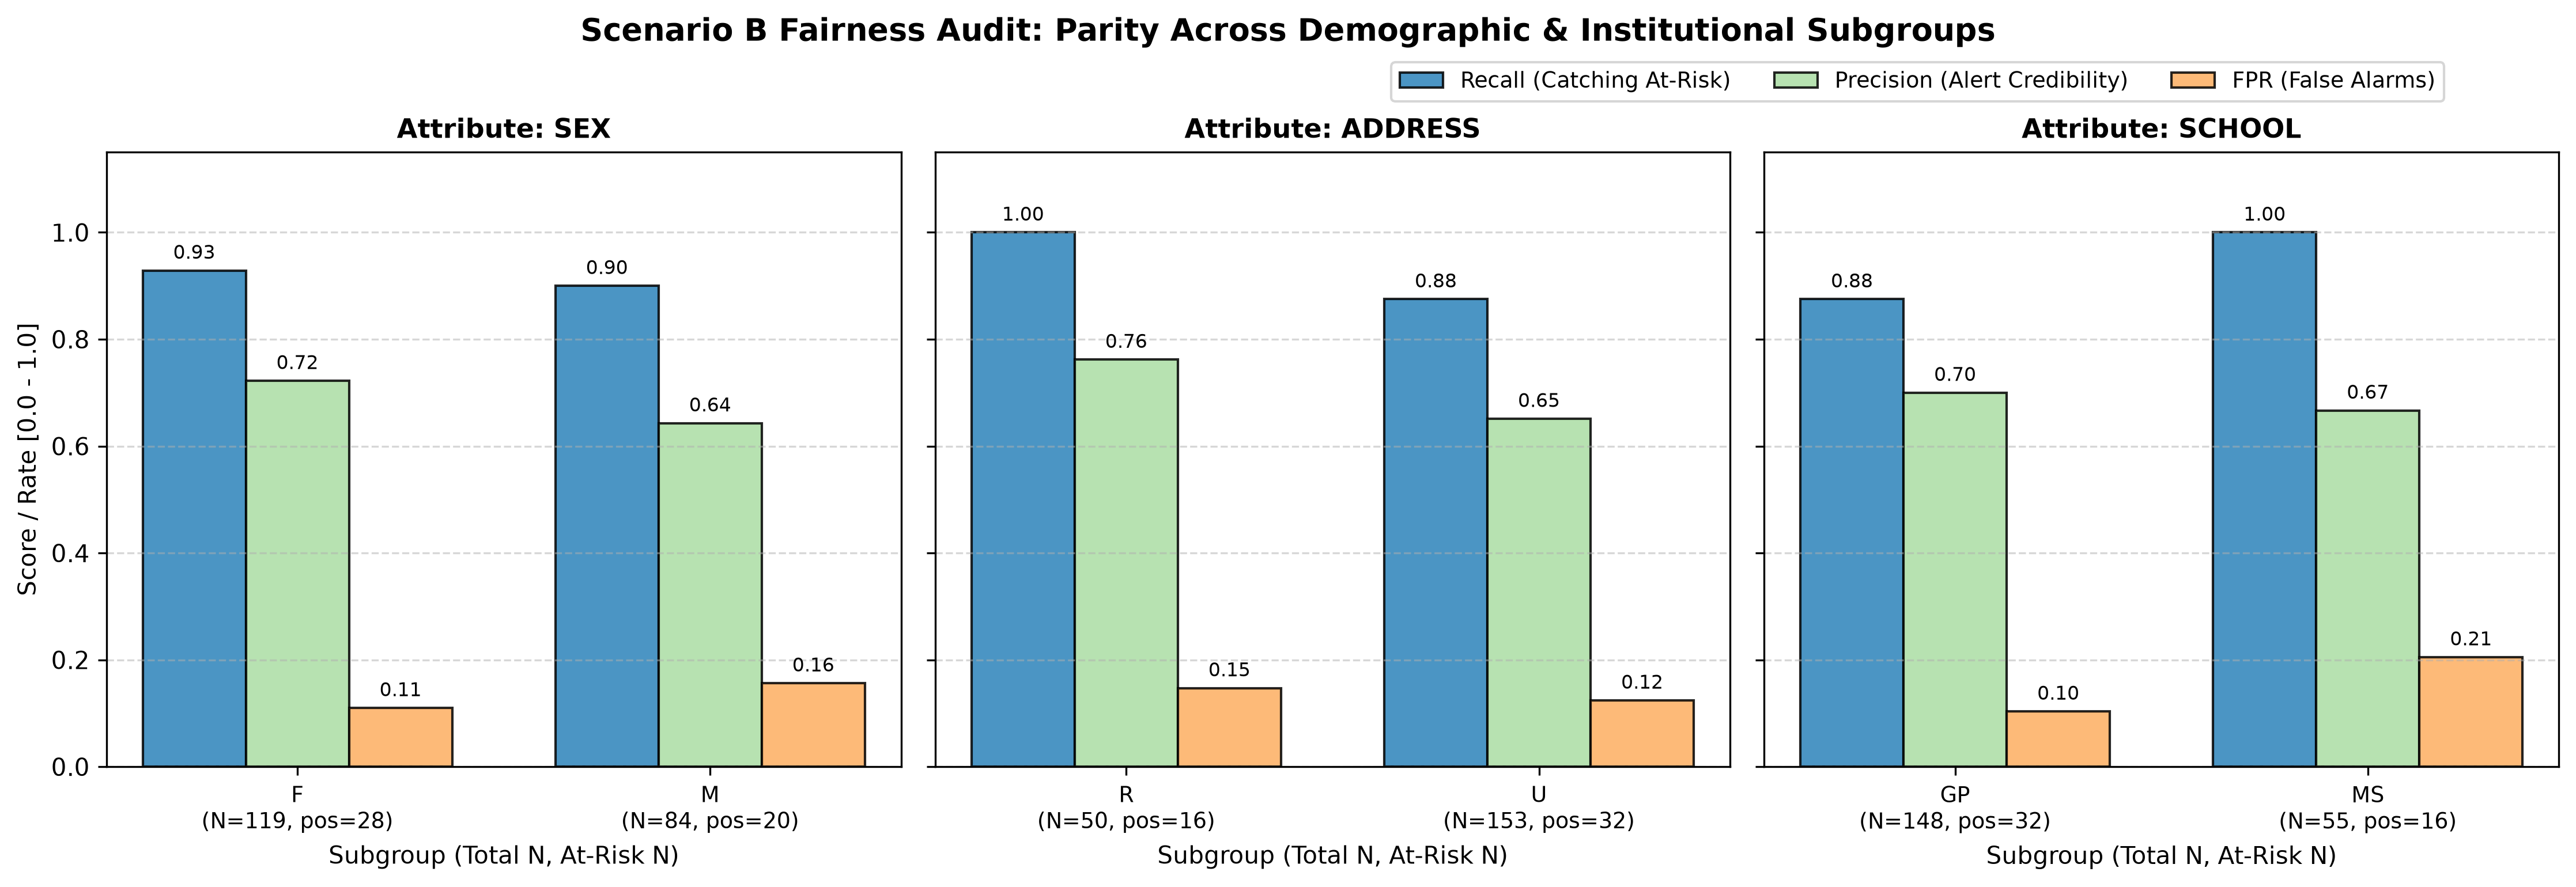

In [7]:
# Display generated subgroup parity comparison chart
print("Subgroup Fairness Parity Comparison Chart:")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "fairness_metrics_scenario_b.png"), width=850))


### 📊 8. Fairness Findings & Statistical Caveats

Let's examine the narrative fairness audit generated by our interpretation helper:


In [8]:
for attr in ["sex", "address", "school"]:
    print(interpret_fairness_audit(fairness_audit_df, attr))
    print("-" * 70)


Fairness Analysis for 'SEX' (F vs. M):
• Equal Opportunity (Recall): High parity achieved. At-risk students in both groups have virtually equal chances of receiving early support (Recall gap: 2.9% across groups).
• Predictive Parity (Precision): Precision gap is 7.9% (F: 72.2%, M: 64.3%). When alerts fire, their credibility is comparable across student backgrounds.
• False Alarm Parity (FPR): False positive rate among passing students varies by 4.6% (Max FPR: 15.6% vs Min FPR: 11.0%).
----------------------------------------------------------------------
Fairness Analysis for 'ADDRESS' (R vs. U):
• Equal Opportunity (Recall): Noticeable recall disparity of 12.5%. One subgroup experiences lower intervention rates.
• Predictive Parity (Precision): Precision gap is 11.1% (R: 76.2%, U: 65.1%). When alerts fire, their credibility is comparable across student backgrounds.
• False Alarm Parity (FPR): False positive rate among passing students varies by 2.3% (Max FPR: 14.7% vs Min FPR: 12.4%).

### 🎓 Summary of Algorithmic Fairness Findings:

1. **Gender (`sex`): Excellent Parity**
   - **Equal Opportunity:** Recall for Females is **$92.9\%$** ($26 / 28$), and Recall for Males is **$90.0\%$** ($18 / 20$). The recall gap is only **$2.9\%$**, achieving near-perfect Equal Opportunity.
   - **Precision:** $72.2\%$ for Females vs. $64.3\%$ for Males.
   - **FPR:** $11.0\%$ for Females vs. $15.6\%$ for Males.
2. **Residence (`address`): High Rural Safety Net with Sample Caveat**
   - The model flagged **$100\%$ ($16 / 16$)** of at-risk rural students with $76.2\%$ precision.
   - **⚠️ Sample Size Caveat:** Rural students represent only $N = 50$ total in the test set with only $16$ at-risk cases. A single misclassification shifts recall by $\pm 6.25\%$. Counselors must not infer institutional bias from small-sample variance.
3. **School (`school`): High Detection Across Campuses**
   - Both campuses achieve high recall ($87.5\%$ for GP, $100.0\%$ for MS).
   - **⚠️ Sample Size Caveat:** School MS has only $N = 55$ students ($16$ at-risk) in the test split.

---

## 🚀 Transition to Stage 6: Actionable Pedagogical Recommendations
In Stage 6, we will convert these SHAP diagnostic insights into **actionable pedagogical interventions** (rule-based recommendation engine and optional Google Gemini LLM synthesis), providing teachers with concrete, student-specific tutoring, habit-formation, and counseling roadmaps.
